# TC5061 - Exploración de datos (UCI Adult)

**Alumno:** Jordan Piero Borda Colque (A01840539)

Este notebook solo contiene la exploración de datos. La limpieza, el entrenamiento, la evaluación y el registro
en MLflow están en `train.py`.

## 0. Configuración

In [1]:
# Librerías
import io
import platform
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Semilla y rutas
SEED = 42
np.random.seed(SEED)
DATA_DIR, FIG_DIR = Path("../data"), Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Colores: azul = <=50K, naranja = >50K
C_NEG, C_POS, C_MID = "#2a78d6", "#eb6834", "#e8e8e6"
PALETA_CLASES = {"<=50K": C_NEG, ">50K": C_POS}
CMAP_DIV = LinearSegmentedColormap.from_list("div", [C_NEG, C_MID, C_POS])
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "font.size": 10,
})

print(f"Python {platform.python_version()} | pandas {pd.__version__}")

Python 3.12.13 | pandas 3.0.6


## Paso 1. Carga y descripción del dataset

- **Fuente:** UCI Adult (censo de EE. UU., 1994). Viene en dos archivos: `adult.data` y `adult.test`.
- **Problema:** clasificación binaria. Predecir si una persona gana más de 50K USD al año (`income`).
- Se unen ambos archivos; la división entrenamiento/prueba se hace en `train.py`.

In [2]:
# Descargar el dataset si no está en data/
URL_UCI = "https://archive.ics.uci.edu/static/public/2/adult.zip"
DATA_DIR.mkdir(exist_ok=True)
if not (DATA_DIR / "adult.data").exists() or not (DATA_DIR / "adult.test").exists():
    with urllib.request.urlopen(URL_UCI, timeout=60) as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(DATA_DIR)
    print("Dataset descargado de", URL_UCI)

# Los archivos no traen encabezado
COLUMNAS = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
            "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
            "hours_per_week", "native_country", "income"]

# adult.test tiene una primera línea de comentario
train_raw = pd.read_csv(DATA_DIR / "adult.data", names=COLUMNAS, skipinitialspace=True)
test_raw = pd.read_csv(DATA_DIR / "adult.test", names=COLUMNAS, skipinitialspace=True, skiprows=1)

df_raw = pd.concat([train_raw.assign(origen="adult.data"),
                    test_raw.assign(origen="adult.test")], ignore_index=True)
print("Registros y columnas:", df_raw.shape)
df_raw.head()

Registros y columnas: (48842, 16)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,origen
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,adult.data
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,adult.data
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,adult.data
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,adult.data
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,adult.data


In [3]:
# Diccionario de datos
SIGNIFICADO = {
    "age": "Edad",
    "workclass": "Tipo de empleador",
    "fnlwgt": "Peso muestral del censo",
    "education": "Nivel educativo (texto)",
    "education_num": "Nivel educativo (1 a 16)",
    "marital_status": "Estado civil",
    "occupation": "Ocupación",
    "relationship": "Rol en el hogar",
    "race": "Raza",
    "sex": "Sexo",
    "capital_gain": "Ganancias de capital (USD)",
    "capital_loss": "Pérdidas de capital (USD)",
    "hours_per_week": "Horas de trabajo por semana",
    "native_country": "País de origen",
    "income": "Objetivo: <=50K o >50K",
}
diccionario = pd.DataFrame({
    "tipo": df_raw[COLUMNAS].dtypes.astype(str),
    "valores_unicos": df_raw[COLUMNAS].nunique(),
    "significado": pd.Series(SIGNIFICADO),
})
diccionario

,tipo,valores_unicos,significado
age,int64,74,Edad
workclass,str,9,Tipo de empleador
fnlwgt,int64,28523,Peso muestral del censo
education,str,16,Nivel educativo (texto)
education_num,int64,16,Nivel educativo (1 a 16)
marital_status,str,7,Estado civil
occupation,str,15,Ocupación
relationship,str,6,Rol en el hogar
race,str,5,Raza
sex,str,2,Sexo


In [4]:
# Tipos y nulos
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  48842 non-null  str  
 14  income          48842 non-null  str  
 15  origen          48842 non-null  str  
dtypes: int64(6), str(10)
memory usage: 10.1 MB


**Resumen:** 48 842 registros y 15 variables (6 numéricas y 9 categóricas, incluido el objetivo).

- pandas no detecta nulos, pero los faltantes vienen escritos como `"?"`.
- `income` tiene 4 valores en lugar de 2: hay un problema de formato.

## Paso 2. Análisis exploratorio (EDA)

### 2.1 Estadísticas descriptivas

In [5]:
# Variables numéricas
num_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
desc_num = df_raw[num_cols].describe().T
desc_num["asimetria"] = df_raw[num_cols].skew()
desc_num["pct_ceros"] = (df_raw[num_cols] == 0).mean() * 100
desc_num.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,pct_ceros
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0,0.56,0.00
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0,1.44,0.00
education_num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,-0.32,0.00
capital_gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0,11.89,91.74
capital_loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0,4.57,95.33
hours_per_week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0,0.24,0.00


In [6]:
# Variables categóricas
cat_cols = ["workclass", "education", "marital_status", "occupation", "relationship",
            "race", "sex", "native_country", "income"]
desc_cat = df_raw[cat_cols].describe().T
desc_cat["n_signo_?"] = (df_raw[cat_cols] == "?").sum()
desc_cat

,count,unique,top,freq,n_signo_?
workclass,48842,9,Private,33906,2799
education,48842,16,HS-grad,15784,0
marital_status,48842,7,Married-civ-spouse,22379,0
occupation,48842,15,Prof-specialty,6172,2809
relationship,48842,6,Husband,19716,0
race,48842,5,White,41762,0
sex,48842,2,Male,32650,0
native_country,48842,42,United-States,43832,857
income,48842,4,<=50K,24720,0


In [7]:
# Etiquetas del objetivo por archivo
df_raw.groupby("origen")["income"].value_counts().unstack(fill_value=0)

income,<=50K,>50K,<=50K.,>50K.
origen,,,,
adult.data,24720,7841,0,0
adult.test,0,0,12435,3846


`adult.test` agrega un punto a la etiqueta (`>50K.`). Para el EDA se usa una copia con la etiqueta corregida;
la limpieza formal se hace en `train.py`.

In [8]:
# Copia para el EDA con objetivo binario
eda = df_raw.copy()
eda["income"] = eda["income"].str.rstrip(".")
eda["y"] = (eda["income"] == ">50K").astype(int)
dist = eda["income"].value_counts()
dist

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

### 2.2 Variable objetivo

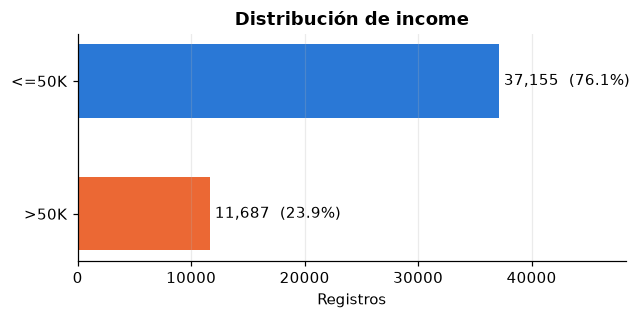

In [9]:
# Gráfica 1. Balance de clases
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(dist.index[::-1], dist.values[::-1], color=[PALETA_CLASES[k] for k in dist.index[::-1]], height=0.55)
for i, v in enumerate(dist.values[::-1]):
    ax.text(v + 400, i, f"{v:,}  ({v / dist.sum():.1%})", va="center")
ax.set_xlim(0, dist.max() * 1.3)
ax.set_title("Distribución de income")
ax.set_xlabel("Registros")
ax.grid(axis="y", visible=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "01_balance_clases.png", bbox_inches="tight")
plt.show()

Las clases están desbalanceadas (76 % `<=50K`). Predecir siempre `<=50K` ya da 76 % de accuracy, por eso
también se usan F1, ROC-AUC y PR-AUC.

### 2.3 Variables numéricas

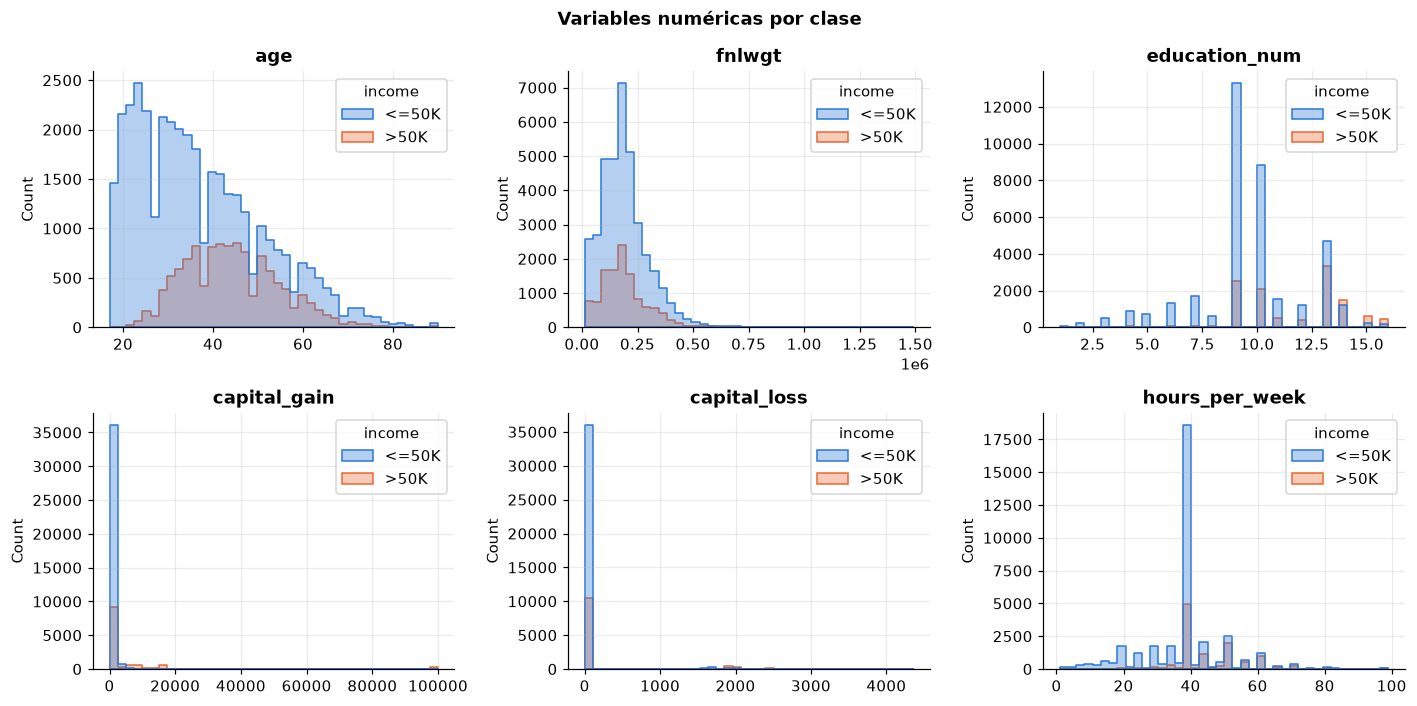

In [10]:
# Gráfica 2. Histogramas por clase
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=eda, x=col, hue="income", hue_order=["<=50K", ">50K"], palette=PALETA_CLASES,
                 bins=40, element="step", common_norm=False, ax=ax, alpha=0.35)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Variables numéricas por clase", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "02_histogramas_numericas.png", bbox_inches="tight")
plt.show()

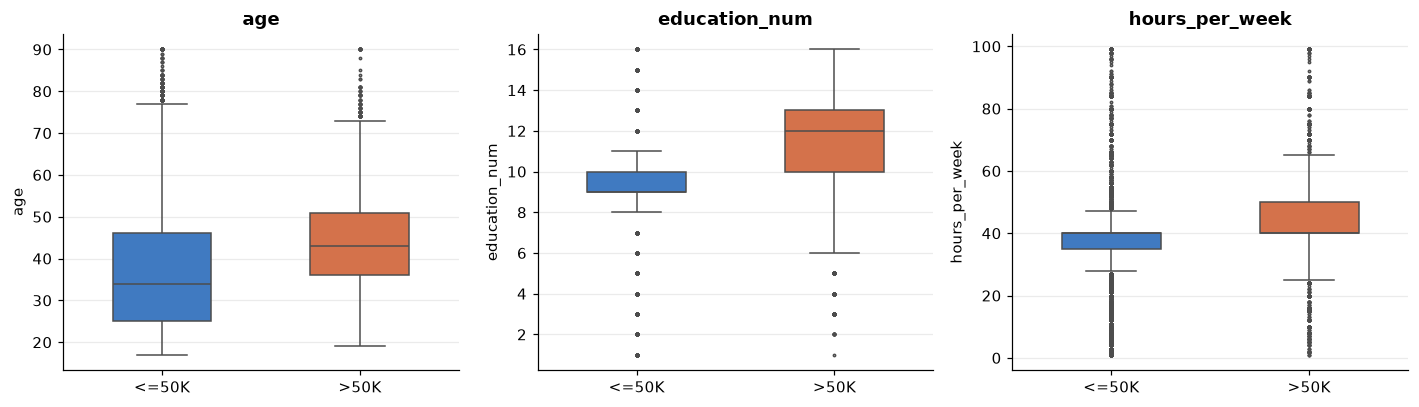

,age,education_num,hours_per_week
income,,,
<=50K,34.0,9.0,40.0
>50K,43.0,12.0,40.0


In [11]:
# Gráfica 3. Boxplots por clase
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ["age", "education_num", "hours_per_week"]):
    sns.boxplot(data=eda, x="income", y=col, order=["<=50K", ">50K"], hue="income",
                palette=PALETA_CLASES, ax=ax, width=0.5, fliersize=1.5, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
fig.savefig(FIG_DIR / "03_boxplots_por_clase.png", bbox_inches="tight")
plt.show()

# Medianas por clase
eda.groupby("income")[["age", "education_num", "hours_per_week"]].median()

- Quienes ganan `>50K` son mayores (mediana 43 vs. 34 años) y tienen más educación (12 vs. 9).
- `hours_per_week` se concentra en 40 horas.
- `capital_gain` y `capital_loss` son casi siempre 0 y tienen colas muy largas.
- `fnlwgt` se distribuye igual en ambas clases.

### 2.4 Variables categóricas

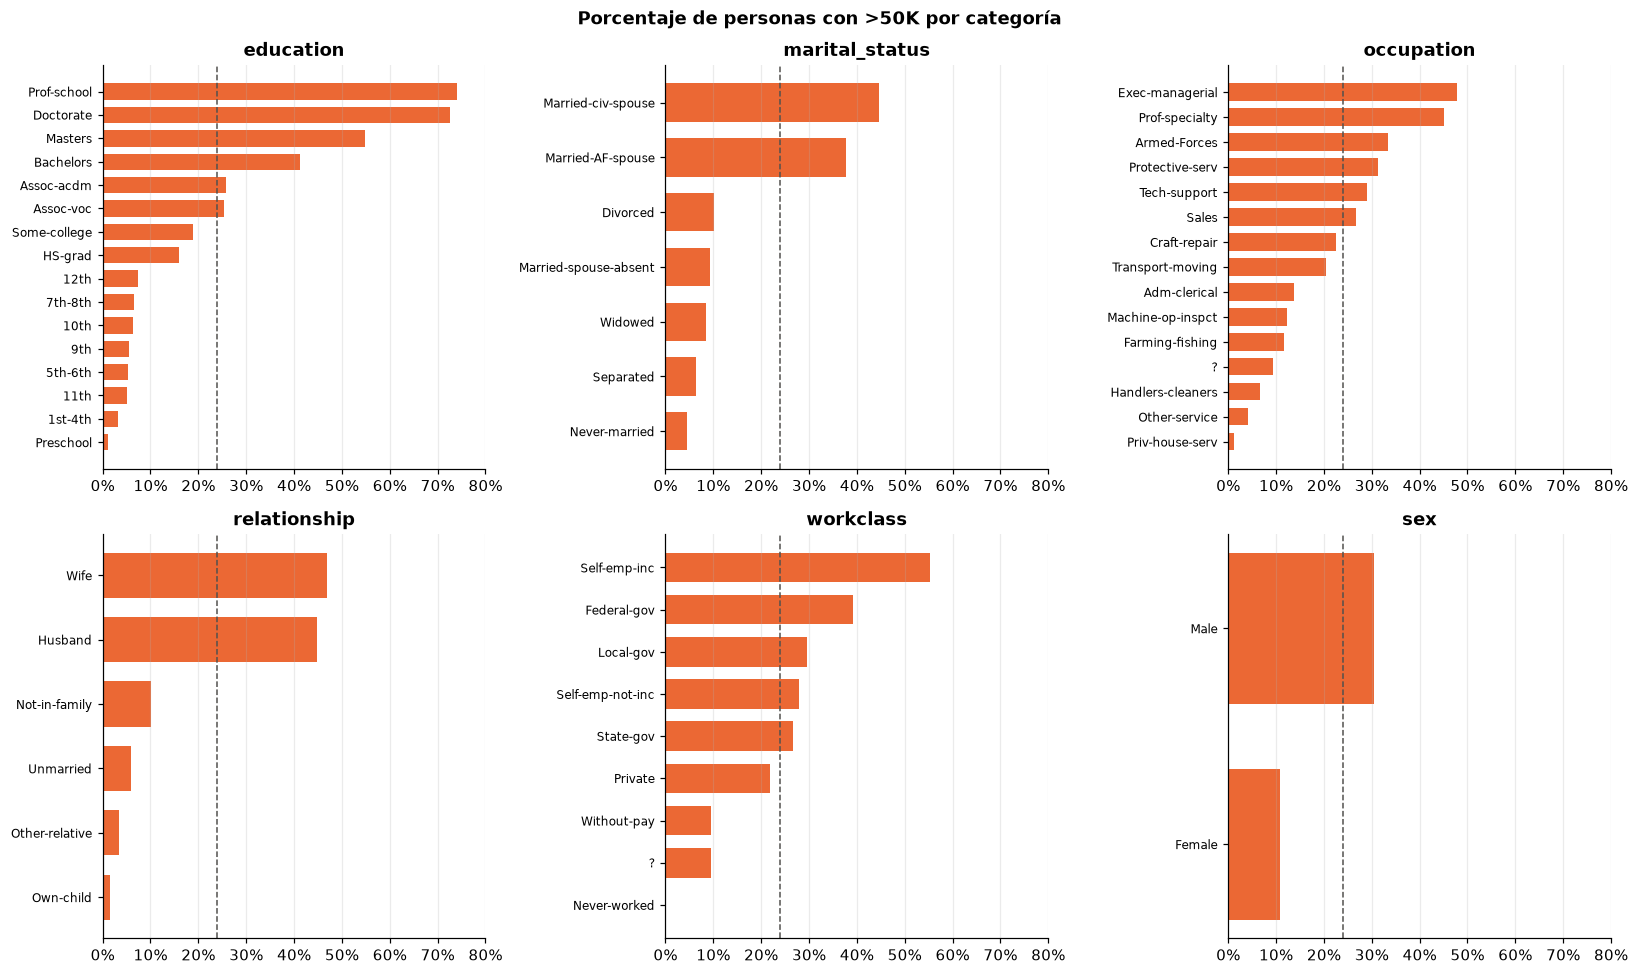

In [12]:
# Gráfica 4. Porcentaje de >50K por categoría (línea = promedio general)
cats_plot = ["education", "marital_status", "occupation", "relationship", "workclass", "sex"]
tasa_global = eda["y"].mean()
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.ravel(), cats_plot):
    tasas = eda.groupby(col)["y"].mean().sort_values()
    ax.barh(tasas.index.astype(str), tasas.values, color=C_POS, height=0.7)
    ax.axvline(tasa_global, color="#52514e", ls="--", lw=1)
    ax.set_title(col)
    ax.set_xlim(0, 0.8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Porcentaje de personas con >50K por categoría", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "04_tasa_positiva_categoricas.png", bbox_inches="tight")
plt.show()

- Las personas casadas (`Married-civ-spouse`, `Husband`, `Wife`) tienen cerca de 45 % de `>50K`; `Never-married` y
  `Own-child` casi no tienen.
- El porcentaje sube con la educación (Doctorate y Prof-school superan 70 %).
- `Exec-managerial` y `Prof-specialty` son las ocupaciones con más ingresos altos.
- Los hombres tienen casi el triple de `>50K` que las mujeres (posible sesgo a vigilar).

### 2.5 Correlaciones

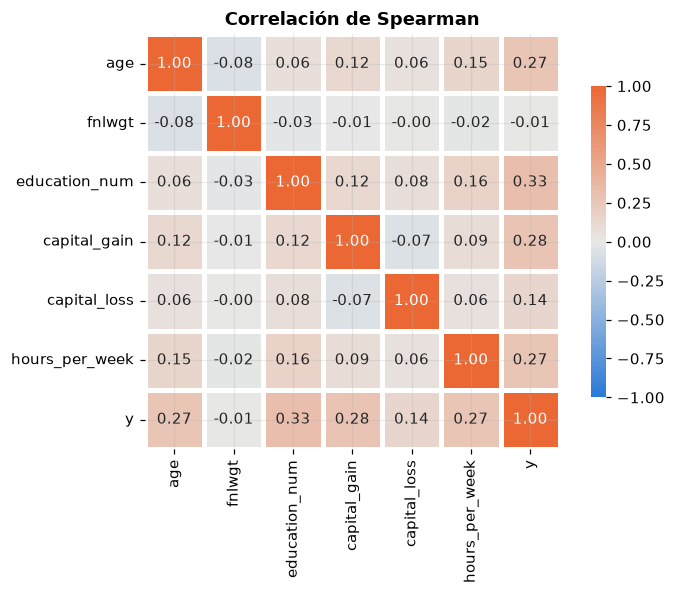

In [13]:
# Gráfica 5. Correlación de Spearman entre numéricas y el objetivo
corr = eda[num_cols + ["y"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=CMAP_DIV, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", square=True, cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Correlación de Spearman")
plt.tight_layout()
fig.savefig(FIG_DIR / "05_correlacion_spearman.png", bbox_inches="tight")
plt.show()

Las numéricas no están muy correlacionadas entre sí. Las más relacionadas con el objetivo son `education_num`,
`age`, `hours_per_week` y `capital_gain`. `fnlwgt` casi no tiene relación (-0.01).

### 2.6 Problemas de calidad encontrados

| Problema | Evidencia |
|----------|-----------|
| Etiquetas inconsistentes | `>50K` y `>50K.` |
| Faltantes ocultos | `"?"` en `workclass`, `occupation`, `native_country` |
| Duplicados | se eliminan en `train.py` |
| Outliers | colas largas en `capital_gain`, `capital_loss`, `hours_per_week` |
| Variables redundantes | `education` repite `education_num`; `fnlwgt` no aporta |
| Tipo incorrecto | `income` es texto; el modelo necesita 0/1 |

Estas decisiones se aplican en la función `limpiar()` de `train.py`.